Enter Grid Size: The Number of Squares Along One Side of a Square Grid 5


The Size of the Hypothetical Spatial System is 5 Zones by 5 Zones, Making 25 in All



Enter the Parameter Value on Distance - beta - that You Think Best Fits the Data 0.5


Zone 	 ObsO 	 ObsD 	 PredO 	 PredD

1 	 27.11 	 37.46 	 20.40 	 27.93
2 	 36.01 	 49.32 	 32.85 	 45.01
3 	 42.94 	 44.05 	 41.30 	 43.05
4 	 40.52 	 38.54 	 36.74 	 35.52
5 	 31.26 	 33.10 	 23.51 	 25.03
6 	 42.73 	 37.61 	 37.91 	 33.94
7 	 48.14 	 48.06 	 52.31 	 53.57
8 	 48.40 	 29.01 	 56.06 	 34.73
9 	 44.58 	 42.54 	 49.15 	 47.99
10 	 33.45 	 35.39 	 30.54 	 32.40
11 	 31.75 	 27.80 	 29.21 	 26.37
12 	 43.39 	 35.51 	 49.31 	 41.85
13 	 47.36 	 46.11 	 58.32 	 58.73
14 	 59.00 	 50.32 	 70.01 	 60.70
15 	 34.20 	 42.21 	 33.55 	 41.17
16 	 32.16 	 34.04 	 27.85 	 30.16
17 	 50.11 	 41.34 	 53.61 	 45.52
18 	 46.69 	 38.69 	 54.62 	 46.21
19 	 59.26 	 64.82 	 67.18 	 73.70
20 	 28.45 	 39.49 	 26.65 	 36.45
21 	 28.28 	 34.27 	 20.40 	 24.90
22 	 28.37 	 28.17 	 25.07 	 25.15
23 	 37.77 	 46.69 	 36.43 	 45.18
24 	 41.03 	 42.76 	 38.28 	 39.66
25 	 37.06 	 32.72 	 28.74 	 25.07


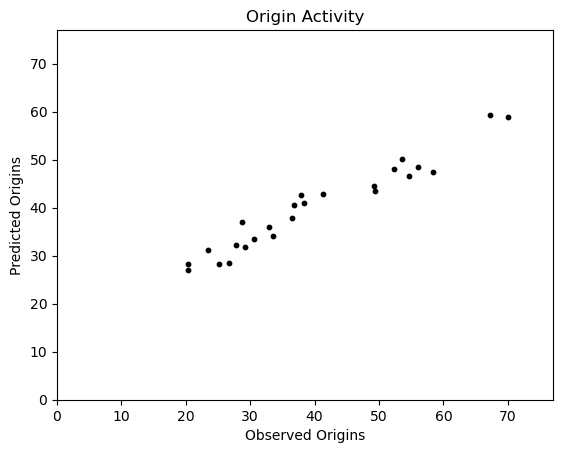

Correlation  	 0.971


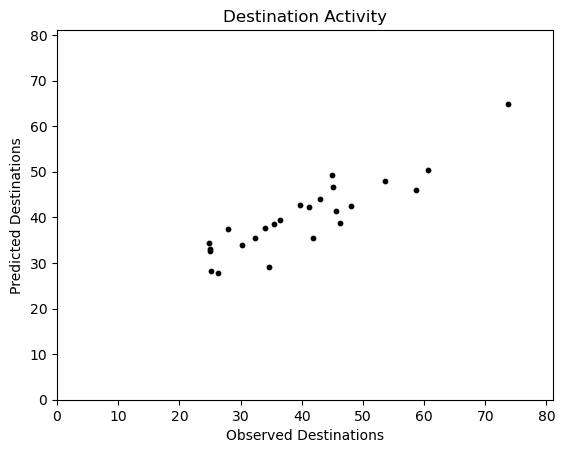

Correlation  	 0.897


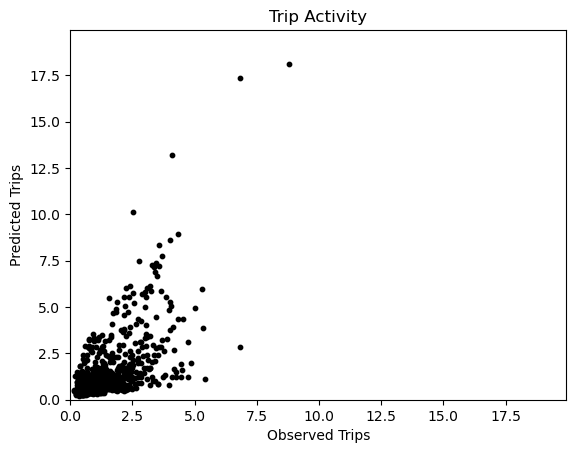

Correlation  	 0.914


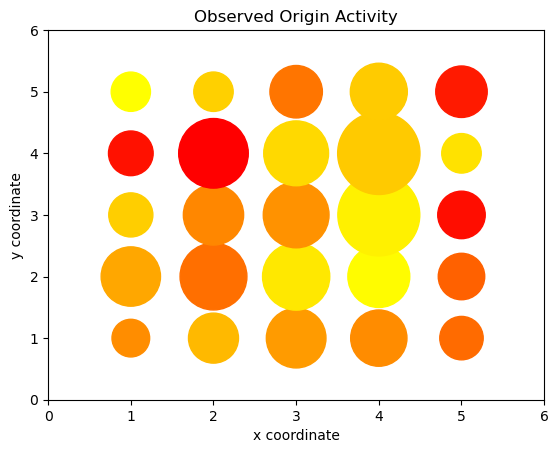

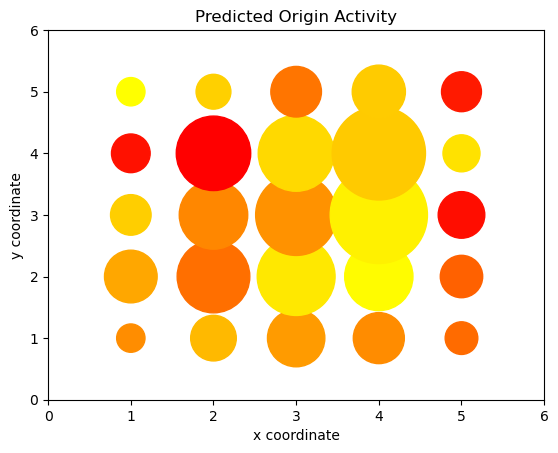

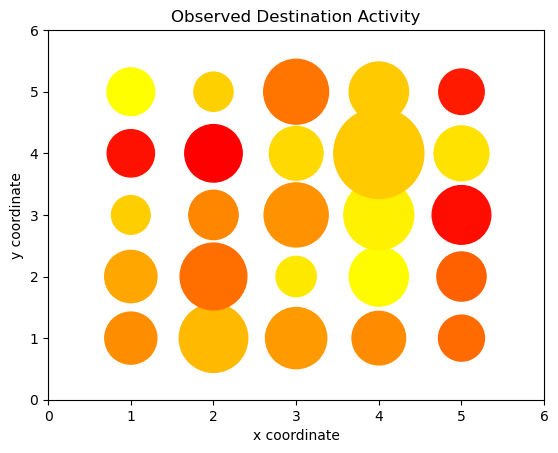

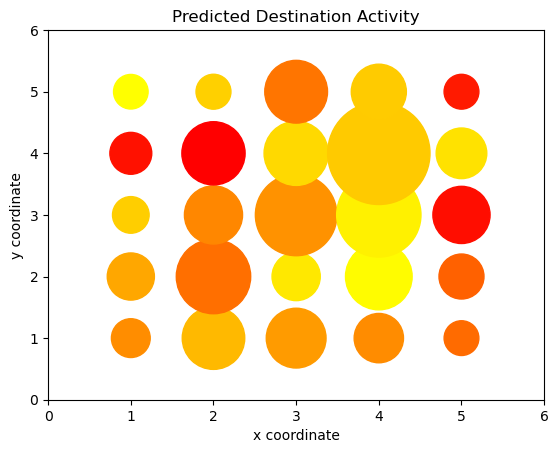

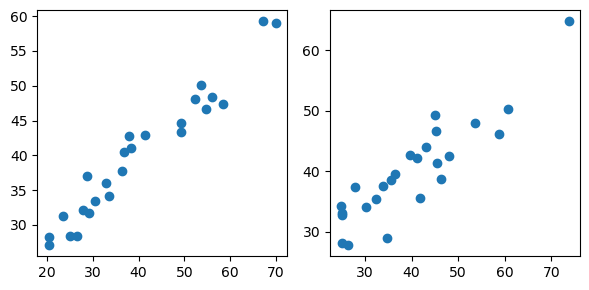

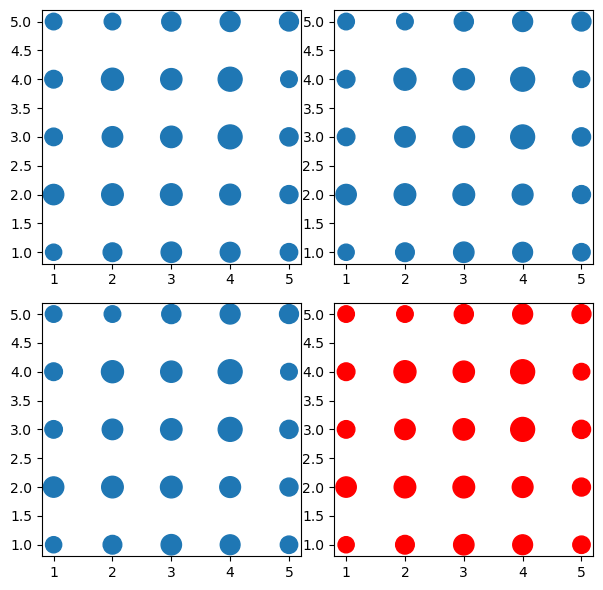

The model and its outputs are now complete

This is a defined function for the scatter



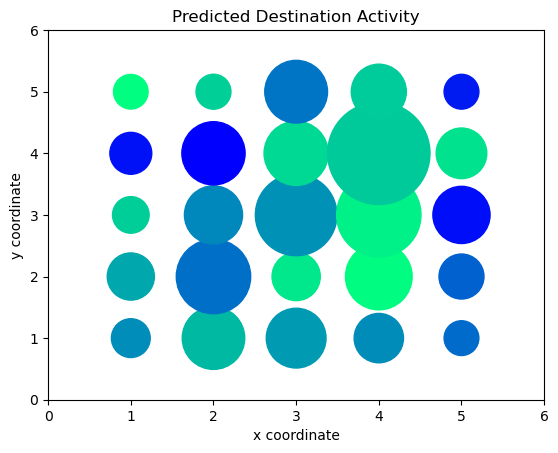

In [5]:
import numpy as np
import math
from matplotlib import pyplot as plt
from numpy import random
import numpy as np
#plt.style.use('seaborn-whitegrid')

#Defining the Hypothetical Spatial System

xcoord=np.array([])
ycoord=np.array([])

n=input("Enter Grid Size: The Number of Squares Along One Side of a Square Grid")
n=int(n); N=n*n
print("The Size of the Hypothetical Spatial System is",n, "Zones by", n,"Zones, Making", N,"in All")
print()

distance=np.full((N,N), 1.0)

n=n+1
for y in range(1,n):
    for x in range(1,n):
        xcoord = np.append(xcoord,[x]) 
        ycoord = np.append(ycoord,[y])

ij=0
for i in range (0,N):
    xi=xcoord[i]
    yi=ycoord[i]
    for j in range (0,N):
        ij=ij+1
        xj=xcoord[j]
        yj=ycoord[j]
        dis=math.sqrt((((xi-xj)**2)+((yi-yj)**2)))
        distance[i][j]=dis
        if distance[i][j]==0:
            distance[i][j]=0.5
        #print(i+1,j+1,distance[i][j])

#Defining the Hypothetical Trip, Origin and Destination Data

tobs=np.full((N,N), 1.0)
origins=np.full((N),1.0)
destinations=np.full((N),1.0)

for i in range (0,N):
    for j in range (0,N):
        tobs[i][j]=1.0/(distance[i][j]*(0.1+random.rand()))
Tobs = np.sum(tobs)
for i in range (0,N):
    for j in range(0,N):
        ij=ij+1
        tobs[i,j]=1000*(tobs[i][j]/Tobs)

origins = np.sum(tobs, axis = 1)
destinations = np.sum(tobs, axis = 0)

#print (origins)
#print (destinations)
To=np.sum(origins) 
Td=np.sum(destinations)
Tobs = np.sum(tobs)
#print("\t","{:.2f}".format(To), "\t","{:.2f}".format(Td), "\t","{:.2f}".format(Tobs))
#print()

#Running the Model

beta=input("Enter the Parameter Value on Distance - beta - that You Think Best Fits the Data")
beta=float(beta)

trips=np.full((N,N),1.0)
OPred=np.full((N),1.0)
DPred=np.full((N), 1.0)

beta=0.5; total=1000
for i in range(0,N):
    for j in range(0,N):
        trips[i][j]=origins[i]*destinations[j]/(math.exp(beta*distance[i][j]))
Ttrip = np.sum(trips)
for i in range(0,N):
    for j in range(0,N):
        trips[i][j]=total*((origins[i]*destinations[j])/(math.exp(beta*distance[i][j])))/Ttrip
sum=0.0;sum1=0.0
for i in range(0,N):
    for j in range(0,N):
        sum=sum+tobs[i][j]
        sum1=sum1+trips[i][j]  

#Printing the Predictions

OPred = np.sum(trips, axis = 1)
DPred = np.sum(trips, axis = 0)

print("Zone","\t","ObsO","\t","ObsD","\t","PredO","\t","PredD")
print()
for i in range(0,N):
    print(i+1, "\t","{:.2f}".format(origins[i]), "\t","{:.2f}".format(destinations[i]),"\t","{:.2f}".format(OPred[i]),"\t","{:.2f}".format(DPred[i]))

#Comparing Observed with Predicted Origin Activity

maxo=np.max(origins); maxop=np.max(OPred)
if maxo>maxop:
    maxv=maxo
else:
    maxv=maxop
maxv=maxv*(1.1)
plt.axis([0,maxv,0,maxv])
plt.xlabel("Observed Origins")
plt.ylabel("Predicted Origins")
plt.title('Origin Activity')
plt.scatter(OPred, origins, s=10,c='black')
input()
plt.show()
rO = np.corrcoef(OPred, origins)
print("Correlation ","\t","{:.3f}".format(rO[0,1]))

maxd=np.max(destinations); maxdp=np.max(DPred)
if maxd>maxdp:
    maxv=maxd
else:
    maxv=maxdp
maxv=maxv*1.1
plt.axis([0,maxv,0,maxv])
plt.xlabel("Observed Destinations")
plt.ylabel("Predicted Destinations")
plt.title('Destination Activity')
plt.scatter(DPred, destinations,s=10,c='black')
input()
plt.show()
rD = np.corrcoef(DPred, destinations)
print("Correlation ","\t","{:.3f}".format(rD[0,1]))

maxt=np.max(tobs); maxtp=np.max(trips)
if maxt>maxtp:
    maxv=maxt
else:
    maxv=maxtp
maxv=maxv*1.1
plt.axis([0,maxv,0,maxv])
plt.xlabel("Observed Trips")
plt.ylabel("Predicted Trips")
plt.title('Trip Activity')
plt.scatter(trips, tobs, s=10,c='black')
input()
plt.show()
rO = np.corrcoef(trips, tobs)
print("Correlation ","\t","{:.3f}".format(rO[0,1]))

rng = np.random.RandomState(0)
colors = rng.rand(N)
sizes=origins**2
plt.axis([0,n,0,n])
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.title('Observed Origin Activity')
plt.scatter(xcoord, ycoord, c=colors, s=sizes, alpha=1.0,cmap='autumn')
input()
plt.show()
sizes=OPred**2
plt.axis([0,n,0,n])
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.title('Predicted Origin Activity')
plt.scatter(xcoord, ycoord, c=colors, s=sizes, alpha=1.0,cmap='autumn')
input()
plt.show()
sizes=destinations**2
plt.axis([0,n,0,n])
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.title('Observed Destination Activity')
plt.scatter(xcoord, ycoord, c=colors, s=sizes, alpha=1.0,cmap='autumn')
input()
plt.show()
sizes=DPred**2
plt.axis([0,n,0,n])
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.title('Predicted Destination Activity')
plt.scatter(xcoord, ycoord, c=colors, s=sizes, alpha=1.0,cmap='autumn')
input()
plt.show()


#fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(6, 6))
fig, axes = plt.subplots(1, 2, figsize=(6,3))
axes[0].scatter(OPred, origins)
axes[1].scatter(DPred, destinations)
fig.tight_layout()
print()
plt.show()

input()
sizes=origins*5
#fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(6, 6))
fig, axes = plt.subplots(2, 2, figsize=(6,6))
axes[0,0].scatter(xcoord, ycoord, s=sizes)
axes[1,0].scatter(xcoord, ycoord, s=sizes)
fig.tight_layout()
print()
axes[0,1].scatter(xcoord, ycoord, s=sizes)
axes[1,1].scatter(xcoord, ycoord, s=sizes, color='r')
fig.tight_layout()
plt.show()

print("The model and its outputs are now complete")
print()
print("This is a defined function for the scatter")
print()
def scattergraph():
    plt.show()
    sizes=DPred**2
    plt.axis([0,n,0,n])
    plt.xlabel("x coordinate")
    plt.ylabel("y coordinate")
    plt.title('Predicted Destination Activity')
    plt.scatter(xcoord, ycoord, c=colors, s=sizes, alpha=1.0,cmap='winter')

scattergraph()